# Synchrotron 2018

RF 2018

This Jupyter notebook is intended as the first chapter of a crash course in the basic theory and observables of astrophysical synchrotron emission, typically observed in the radio band, and specifically in the context of radio transients and variables. 

It allows you to extract the most basic, and yet often surprisingly fundamental, physics from the data. Once the basics are established, it then moves on to consider one of the simplest models for variable radio emission, that of van der Laan 1966. This model is still relevant today and the underlying equations are the same as those used in more sophisticated models (which will be dealt with in the next chapter).

You may want to read it through once first, and then go back and play with running the individual cells. Once you've understood what the cells are doing, feel free to hack them. If you do something which you consider useful and an improvement, please let me know.

## Definitions and notation

> **Convention:** $S_\nu$ is observed flux density, $I_\nu$ is specific intensity, and $\mathcal S_\nu$ is the source function. Use $S_\nu\propto\nu^\alpha$ throughout.

| Symbol | Definition | Units / convention |
| --- | --- | --- |
| $S_\nu$ | Flux density received from the whole apparent source | mJy in plots; cgs in equations |
| $I_\nu$ | Intensity per unit solid angle | erg s$^{-1}$ cm$^{-2}$ Hz$^{-1}$ sr$^{-1}$ |
| $\mathcal S_\nu$ | Source function $\epsilon_\nu/\kappa_\nu$ | Same units as $I_\nu$ |
| $L_\nu$ | Emitted luminosity per unit frequency | erg s$^{-1}$ Hz$^{-1}$ |
| $B$, $\Phi_B$ | Magnetic field strength; magnetic flux through a specified surface | gauss; gauss cm$^2$ |
| $\gamma$ | Electron Lorentz factor, $E/(m_ec^2)$ | Dimensionless |
| $N_0$, $p$ | Normalisation and index of $N(E)=N_0E^{-p}$ | $N_0$: cm$^{-3}$ erg$^{p-1}$ when $E$ is in erg |
| $\alpha$ | Observed spectral index | $\alpha=(1-p)/2$ for an optically thin power-law segment |
| $R$, $s$, $D$ | Source radius, effective line-of-sight depth, distance | cm |
| $f$, $\eta$ | Emitting-volume fraction; $1+E_p/E_e$ | Dimensionless |
| $\tau_\nu$ | Optical depth $\kappa_\nu s$ | Dimensionless |
| $\nu_g$, $\nu_1$, $\nu_{\rm peak}$ | Non-relativistic gyrofrequency; optical-depth-one frequency; spectral peak | Hz; these are different frequencies |

Conversions: $1\,\mathrm{GHz}=10^9\,\mathrm{Hz}$, $1\,\mathrm{mJy}=10^{-26}\,\mathrm{erg\,s^{-1}\,cm^{-2}\,Hz^{-1}}$, and $1\,\mathrm{kpc}\simeq3.1\times10^{21}\,\mathrm{cm}$.

#### First some constants and set up: you need to run the cell below
**Notation:** observed flux density follows the original convention $S_\nu$; the source function is always $\mathcal S_\nu$. These symbols denote different quantities.


In [1]:
import numpy as np
import math
import scipy.constants
from synchrotron_plotting import (
    plot_linear_log, plot_energy_budget, plot_spectra,
    plot_lightcurves, plot_plasma_evolution, animate_evolution, show_figure,
)
# Plotting is imported; physical equations and constants stay in this notebook.
%matplotlib inline
# these are in cgs
# speed of light :)
c=3.0e10
# relativistic sound speed of c/sqrt[3]
cs=c/(3.0**0.5)
# Boltzmann's constant
kb=1.38e-16

# we'll quite often want to infer physical size and/or volume from variability timescale
# as our sources are often not spatially resolved
# we usually do this by assuming some constant expansion speed (c is a maximum, cs is often chosen)
# at any time, if you have an alternative way of estimating r, V (e.g. resolved emission), set them directly

def sizefromt(t,exp):
    r=t*exp
    V=(4.0/3.0)*np.pi*(r**3.0)
    return r,V

# solid angle for a source of size s and distance d (small angle approximation)
def solidangle(r,d):
    omega=np.pi * (r**2.0) / (d**2.0)
    return omega
    


## Part 1: basic physics from simple observables

### Synchrotron and Cyclotron radiation

Nearly everything in this section is better 
explained, albeit at greater length, in 
*High Energy Astrophysics* by Longair, 
and I recommend everyone get a copy.

https://www.amazon.co.uk/High-Energy-Astrophysics-Malcolm-Longair/dp/0521756189

Synchrotron emission arises whenever 
relativistic electrons (or positrons) accelerate in a magnetic field (‘spiral around the field lines’) due to the $v \times B$ component of the Lorentz force. It is the relativistic version of cyclotron radiation. 

<hr />

An electron with a Lorentz factor $\gamma$ radiates a broad spectrum of synchrotron radiation, with an approximate characteristic frequency of

$$\nu_{\rm char} \sim \gamma^2 \nu_g$$

where $\nu_g$ is the non-relativistic cyclotron frequency

$$\nu_g=\frac{|q|B}{2\pi m}\quad\mathrm{(SI)},\qquad
\nu_g=\frac{|q|B}{2\pi mc}\quad\mathrm{(Gaussian\ cgs)}.$$

Synchrotron radiation is emission by charges accelerated in a magnetic field; it is not literally inverse Compton scattering of cyclotron photons. The actual relativistic orbital frequency is $\nu_g/\gamma$, while beaming and arrival-time compression produce high-frequency synchrotron pulses. The standard critical frequency is $\nu_{\rm crit}=(3/2)\gamma^2\nu_g\sin\theta$; the usual single-electron spectrum peaks near $0.29\nu_{\rm crit}$. The estimator below uses the simpler characteristic-frequency scaling.

Inserting constants, we can easily calculate $\nu_{\rm char}$ for a given $\gamma$ and $B$

$$\nu_{\rm char} = 2.8 \times 10^6 \gamma^2 B$$ Hz

where in this formula $B$ is in Gauss.

Reversing this, if we observe synchrotron radiation at some frequency, and can estimate $B$, we can estimate the Lorentz factor of the radiating electrons

$$\gamma = \sqrt{\frac{\nu_{\rm char}}{2.8 \times 10^6 B}}$$

The following code snippet is simple $\gamma$-estimator you can use.

In [2]:
### USER INPUT VARIABLES HERE ###
# set your observing frequency in GHz
nu=15.0
# convert to Hz
nuc=nu*1e9
# set your estimate of B in Gauss. How would you estimate this you ask? 
# soon you will see that the equipartition assumption gives you one route
# evidence for or against synchrotron losses also helps to constrain it
B=0.3
#################################

# this is the formula for gamma from nuc and B given above
gamma=(nuc/(B*2.8e6))**0.5

# observing frequency i
# Total electron energy including rest energy, in keV; kinetic energy is 511*(gamma-1). (rest energy of electron is 511 keV)
energy=511.0 * (gamma)
energyerg=energy*1.6e-9
# NB this 511.0 * 1.6e-9 = 8.2e-7 is the electron-gamma-to-erg conversion factor used later on

print ('Emission at ',('%.2e' % nu),(' GHz, in a magnetic field of '),('%.2e' % B),(' Gauss:'))
print ('Lorentz factor of emitting electrons',('%.2e' % gamma))
print ('Total energy of electrons is',('%.2e' % energy),' keV = ',('%.2e' % energyerg),' erg')

Emission at  1.50e+01  GHz, in a magnetic field of  3.00e-01  Gauss:
Lorentz factor of emitting electrons 1.34e+02
Total energy of electrons is 6.83e+04  keV =  1.09e-04  erg


Emission observed at 1.50e+01  GHz, relation between B and gamma of emitting electrons:


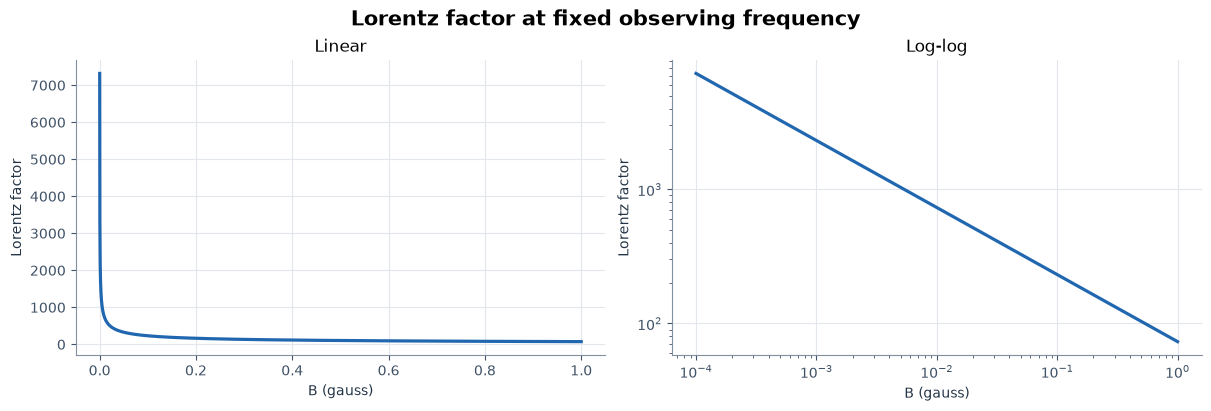

In [3]:
### USER INPUT VARIABLES HERE ###
# We can also plot the relation between gamma and B
# input here your likely lower and upper limits to B, we'll make linear and log plots
b1=1.0e-4
b2=1.0
#################################

x=np.linspace(b1,b2,10000)
y=(nuc/(x*2.8e6))**0.5
  
print( ("Emission observed at"), ('%.2e' % (nuc/1.0e9)),(' GHz, relation between B and gamma of emitting electrons:') )  
show_figure(plot_linear_log(x, y, "B (gauss)", "Lorentz factor",
                            title="Lorentz factor at fixed observing frequency"))


## Brightness temperature calculators

The brightness temperature associated with any emitting region is the temperature a black body of the same size would require in order to produce the same flux at that frequency. It can be a good constraint on the emission
physics at play. For incoherent synchrotron sources, $T_B\sim10^{12}$ K is an approximate inverse-Compton limit in the source rest frame, under the standard source assumptions. It is not an unconditional ceiling. Apparent excesses can involve Doppler boosting, source geometry/variability assumptions, or coherent emission.

> **Definition:** brightness temperature is the Rayleigh-Jeans temperature associated with an intensity; it does not require the synchrotron plasma to be thermal.

### B1 Brightness temperature from integrated flux and angular size

Using the Rayleigh-Jeans tail of the Planck black-body function we get:

$$T_B = \frac{S_{\nu} c^2}{2 k_B \Omega \nu^2} = \frac{S_{\nu} c^2 D^2}{2 \pi k_B \nu^2 R^2}$$

The relation between physical size, distance and solid angle for a (circular) object, is given by:

$$\Omega = \frac{\pi R^2}{D^2}$$

**Angular-size convention:** the numerical calculator defaults to full diameters of a uniform ellipse. If the supplied sizes are Gaussian FWHM axes, choose `source_geometry="gaussian_fwhm"`; the solid angle is larger by $1/\ln2$ and the derived brightness temperature is smaller by $\ln2$.


In [4]:
### USER INPUT VARIABLES HERE ###
# flux density in mJy
s=9.0
# observing frequency in GHz
nu=8.6
# angular sizes (two axes) in arcseconds
a1=0.04
a2=0.04
source_geometry="uniform_ellipse"  # alternatively: "gaussian_fwhm"
#####################

# convert flux density to proper units
s=s*1e-26
# convert frequency to proper units
nuc = nu * 1e9

# here I convert to angular sizes to degrees, multiply to get square degrees, convert to steradians
# 1sr = 3282.8 deg^2
a1=a1/3600.0
a2=a2/3600.0
aa=a1*a2
# add in here a geometrical factor, otherwise you just get a rectangle on the sky
# pi/4 is the appropriate factor for an ellipse
if source_geometry == "uniform_ellipse":
    aa=aa*(np.pi/4.0)
elif source_geometry == "gaussian_fwhm":
    aa=aa*(np.pi/(4.0*np.log(2.0)))
else:
    raise ValueError("Choose uniform_ellipse or gaussian_fwhm for source_geometry.")

omega=(aa)/3282.8

def brightnesstemp (s,omega,nuc):
    tb=(s * c**2) / (2 * kb * omega * nuc**2)
    return tb
 
tb=brightnesstemp(s,omega,nuc)
    
print ('Brightness temperature for resolved radio source')
print ('or lower limit for unresolved source')
print (('T_B ='),('%.2e' % tb),('K'))

Brightness temperature for resolved radio source
or lower limit for unresolved source
T_B = 1.34e+05 K


### B2 Brightness temperature inferred from variability timescale

We can also constrain the size of the emitting region from the variability timescale, estimating R from $\Delta t$, if we have some distance estimate for our source, using the expression for solid angle.

In [5]:
### USER INPUT VARIABLES HERE ###
# S in mJy
s=2.0
# D in kpc
d=8.0
# observing frequency in GHz
nu=8.6
# variability timescale in seconds
t=3600.0
# expansion speed (usually c or cs)
vexp=c
#####################

nuc=nu*1e9
s=s*1e-26
d=d*3.1e21
(r,V)=sizefromt(t,vexp)

omega=solidangle(r,d)

tb=brightnesstemp(s,omega,nuc)

print ('Lower limit on brightness temperature from variability')
print (('T_B >'),('%.2e' % tb),('K'))


Lower limit on brightness temperature from variability
T_B > 1.48e+07 K


## Minimum Energy

Burbidge showed back in the 1950s that via a very simple argument you can demonstrate that a synchrotron-emitting plasma contains a lot of energy. You can already sense this from the fact that you have GHz-frequency radio emission (i.e. low-frequency photons) coming from (as we showed earlier) very highly relativistic electrons. 

For a given synchrotron emitting volume, the total energy in the relativistic electrons
$E_e \propto B^{−3/2}$ and that stored in the magnetic field $E_B \propto B^2$.


While there could be other contributors to the total energy of some synchrotron emitting blob (perhaps component of bulk motion, some population of non radiating particles) the minimum requirements are simply the two components above.  There are many caveats to this approach – please read discussion in Longair. In particular the emitting volume may be only some fraction of the total volume of the astrophysical source (i.e. need to consider a ‘filling factor’)

> **Key result:** there is a minimum in the total energy as a function of B. This magnetic field is often called the equipartition field because the minimum energy condition occurs when the total energies in particles and magnetic field are very similar,

$$E_{B} = \frac34 E_e$$

It is very important to stress that this is *not* the minimum magnetic field, it is the magnetic field corresponding to minimum energy.

***

### E1: a simple estimation of minimum energy and equipartition field

A simplified formula, from Longair, corresponding specifically to the case of spectral index $\alpha = -0.75$ (a bit steep, but not unreasonable), gives

$$E_{\rm min, SI} \sim 3 \times 10^6 \eta^{4/7} V^{3/7} \nu^{2/7} L_{\nu}^{4/7}$$

J, where $V$ is in m$^3$, $L_{\nu}$ is in W Hz$^{-1}$ and $\nu$ is in Hz

where $V$ is the volume of the emitting region in m$^3$, $\nu$ is the observed frequency in Hz, $L_\nu$ is the specific luminosity in W Hz$^{-1}$.

Note $\eta = 1 + \beta$ (dimensionless) parametrizes the energy in protons: the ratio of energy in protons to that in electrons is given by $\epsilon_{\rm p} = \beta \epsilon_{e}$.  Ignoring the protons entirely (usually the default position for synchrotron sources) therefore means $\eta=1$.

The magnetic field corresponding to this minimum energy is given by

$$ B_{\rm min E, SI} = 1.8 \left( \frac{\eta L_{\nu}}{V} \right)^{2/7} \nu^{1/7} $$

Tesla.

We can convert this to the cgs unit system we are using:

$$E_{\rm min, cgs} \sim 8 \times 10^6 \eta^{4/7} V^{3/7} \nu^{2/7} L_{\nu}^{4/7}$$

erg, where $V$ is in cm$^3$, $L_{\nu}$ is in erg s$^{-1}$ Hz$^{-1}$ and $\nu$ remains in Hz (note that the constant hardly changes as the factors accomodating the larger values of volume and luminosity in cgs are almost exactly offset by the switch from J to erg).

In cgs units the equipartition field is given by

$$ B_{\rm min E, cgs} = 9 \times 10^3 \left( \frac{\eta L_{\nu}}{V} \right)^{2/7} \nu^{1/7} $$

Gauss.




**Numerical consistency:** the quoted coefficients are rounded independently. The code derives $B_{\rm eq}=\sqrt{24\pi E_{\min}/(7V)}$ from the energy estimate so that the plotted minimum satisfies $E_B=3E_{\min}/7$ exactly. For $\eta>1$, replace electron energy by total particle energy in the minimum condition. The simplified estimate assumes $\alpha=-0.75$, takes the observing frequency as the lower cutoff, and neglects the upper-cutoff contribution to electron energy.


Physical size and volume from timescale and expansion at speed 3.00e+10 cm/sec
t= 1.80e+03 s, r= 5.40e+13 cm, V= 6.60e+41 cm^3
Calculated specific luminosity
L = 7.31e+21  erg / sec / Hz
Minimum Energy
E ~ 1.50e+40 erg
The corresponding magnetic field is
B ~ 4.95e-01 Gauss
And so the total energy in magnetic fields is
6.43e+39  erg
Lorentz factor of emitting electrons for this field is
8.49e+01


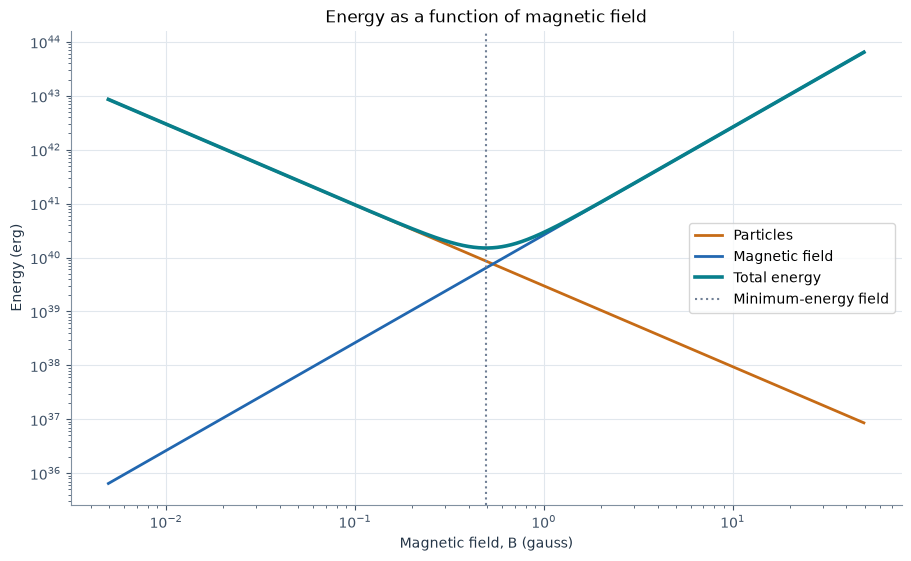

In [6]:
### USER INPUT VARIABLES HERE ###
eta = 1.0
# Emitting volume in cubic centimetres: you set this directly e.g.
# V=1e36
# or you can calculate it for some assumed geometry and variability timescale
# Infer radius from variability; here use c, or choose cs explicitly below.
t=1800.0
vexp=c
# Observing frequency in GHz
nu=10
nuc=nu*1e9

# specific luminosity, you can define directly:
# L=1.0e30
# in which case comment out all of the next lines to 'E='

# or you can calculate from observed flux density and distance
# flux density in mJy
s = 50.0
# Distance in kpc
D = 11.00
#####################

(r,V)=sizefromt(t,vexp)

print (('Physical size and volume from timescale and expansion at speed'),('%.2e' % vexp),('cm/sec'))
print('t= %.2e s, r= %.2e cm, V= %.2e cm^3' % (t,r,V))

def Lum(s,D):
    L = (s * 1e-26) * 4 * np.pi * (D * 3.1e21)**2
    print ('Calculated specific luminosity')
    print (('L ='),('%.2e' % L),(' erg / sec / Hz'))
    return L

L=Lum(s,D)

def MinE(eta,V,nuc,L):
    E=(8.0e6) * (eta**(4.0/7.0)) * (V**(3.0/7.0)) * (nuc ** (2.0/7.0)) * (L ** (4.0/7.0))

    print ('Minimum Energy')
    print (('E ~'),('%.2e' % E),('erg'))

# Now we will calculate the corresponding B field

    # E_B = 3 E_min / 7; derive B consistently with the rounded energy formula.
    Beq=np.sqrt(8*np.pi*(3.0/7.0)*E/V)

    print ('The corresponding magnetic field is')
    print (('B ~'),('%.2e' % Beq),('Gauss'))
    print ('And so the total energy in magnetic fields is')
    Eb=(V*(Beq**2.0))/(8*np.pi)
    print (('%.2e' % Eb),(' erg'))
    geq=(nuc/(Beq*2.8e6))**0.5
    print ('Lorentz factor of emitting electrons for this field is')
    print (('%.2e' % geq))
    return E,Beq,geq

(E,Beq,geq)=MinE(eta,V,nuc,L)

# We can finish this by plotting how the Energy 
# will vary around this minimum with varying B

x=np.geomspace(Beq/100, Beq*100, 10001)
# At the energy minimum, particles carry 4/7 and the field carries 3/7.
Eparticles=(4.0/7.0)*E*(x/Beq)**(-1.5)
Eb=V*x**2/(8*np.pi)
Etot=Eparticles+Eb
show_figure(plot_energy_budget(x, Eparticles, Eb, Beq, savepath="output/graphs/Min_E.png"))


***
***
***
***

## Part 2: Synchrotron emission from a power-law distribution of electrons

We now move on to the most commonly-observed situation for astrophysical synchrotron emission, namely that the emission arises from a broad distribution of relativistic electrons which can be represented by a power law. 

$$N(E) dE = N_0 E^{-p} dE$$

between some limits $E_1,E_2$, where N(E) is a number density (*not* a total number). There is good theoretical and observational evidence that such distributions are often a good description of the underlying particle distribution. 

The figure below illustrates the typical synchrotron spectrum from a single source with such a power-law distribution of electrons. We will learn how to calculate these regions shortly, but first familiarise yourself with the spectrum, noting

1. The self-absorbed part of the spectrum has a spectral index +2.5, not the +2.0 associated with thermal emission (in simple terms, this is because the emission observed does not come from electrons at a single temperature, but rather from a population whose effective temperature varies as $T_{\rm eff} \propto \nu^{1/2}$)

2. In the optically thin branches, the spectral index is directly related to the power-law index of the underlying electron distribution. For an optically thin power-law segment, its slope gives the index of the current electron distribution. If cooling has changed that distribution, it need not be the injected index. Using this convention, $p=1-2\alpha$ for the definition of spectral index as 

$$\alpha = \frac{\log \left( \frac{S_{\nu_1}}{S_{\nu_2}} \right)}{\log \left( \frac{\nu_1}{\nu_2} \right)}$$

i.e. $S_{\nu} \propto \nu^{\alpha}$

(unfortunately it is necessary to check this in pretty much each and every paper you read as the reverse definition,  $S_{\nu} \propto \nu^{-\alpha}$ is also in widespread usage including, notably, Longair's *High Energy Astrophysics*)

<img src='output/figures/ss.png'>

In order to go further, we need to consider the optical depth, emission and absorption coefficients associated with a synchrotron source. We follow the approach of Pacholcyzk (1970), *Radio Astrophysics*, which requires us to define some constants (using his notation, and in cgs units)

$c_1 = \frac{3 e}{4 \pi m^3 c^5} = 6.27 \times 10^{18}$

$c_5 = (2.26, 1.37, 0.97) \times 10^{-23}$ for $p=(1.5,2.0,2.5)$

$c_6 = (9.69, 8.61, 8.10) \times 10^{-41}$ for $p=(1.5,2.0,2.5)$

The frequency at which the optical depth $\tau = 1$ is given by

$$\nu_1 = 2 c_1 (s c_6)^{\frac{2}{p+4}} N_0^{\frac{2}{p+4}} B^{\frac{p+2}{p+4}}$$

Hz. I have made the (common) approximation that $B sin \theta \sim B$. The variable s is the thickness (depth) of the source along the line of sight, assumed to be constant for the source (although it can, and will, vary with time for a variable source, as we shall see later).


This frequency $\nu_1$, is close to the peak of the spectrum as it transitions from optically thick to thin.  It is not exactly at the peak, however, which occurs at 

$$\nu_m = \frac{\nu_1}{\tau_m^{\frac{2}{p+4}}}$$

and the optical depth at peak, $\tau_m = 0.35$ for $p=2$, which in turn leads to $\nu_m = 1.4 \nu_1$.

> **Definitions:** $\epsilon_\nu$ is the emission coefficient; $\kappa_\nu$ is the absorption coefficient. Their full derivation is not included here.

The **emission** and **absorption** coefficients for synchrotron radiation are, as a function of frequency $\nu$,

$$\epsilon_{\nu} = c_5 N_0 B^{\frac{p+1}{2}} \left( \frac{\nu}{2c_1} \right)^{\frac{1-p}{2}}$$

$$\kappa_{\nu} = c_6 N_0 B^{\frac{p+2}{2}} \left( \frac{\nu}{2c_1} \right)^{\frac{-(p+4)}{2}}$$

> **Definition:** the source function is emission divided by absorption: 

$$\mathcal{S}_{\nu} = \frac{\epsilon_{\nu}}{\kappa_{\nu}} = \frac{c_5}{c_6} B^{-\frac12}  \left( \frac{\nu}{2c_1} \right)^{\frac52}$$

We use $\mathcal{S}_\nu$ only for the source function, $I_\nu$ for intensity, and $S_\nu$ for observed flux density.

> **Key result — uniform-source transfer:** the intensity emerging from depth $s$, with no incident background, is:

$$I_{\nu} = \mathcal{S}_{\nu} (1 - e^{-\tau})$$

where the optical depth $\tau = \kappa s$.

In the optically thin limit, $\tau \ll 1$, $I_{\nu} = \epsilon_{\nu} s$ (via Taylor expansion), and so $I_{\nu} \propto \nu^{\frac{1-p}{2}}$ as we saw earlier for the optically thin branch in the absence of synchrotron (or inverse Compton) losses. **Measuring the spectral index in the optically thin branch, in the absence of significant radiation losses directly measures p**.

In the optically thick limit, $\tau \gg 1$, $I_{\nu} = \mathcal{S}_{\nu}$, and so $I_{\nu} \propto \nu^{\frac52}$, i.e. the spectral index of the self-absorbed part is independent of $p$ and is steeper than thermal, self-absorbed, emission (again, as we saw earlier).  **Measuring the spectral index in the optically thick branch does not directly determine $p$**.

We can now move towards calculating the entire synchrotron spectrum for a given set of parameters.

The specific intensity at a frequency $\nu$ can be given by:

$$I_{\nu} = \mathcal{S}_{\nu_1} J \left( \frac{\nu}{\nu_1}, p \right)$$

where $\mathcal{S}_{\nu_1}$ is the source function calculated at frequency $\nu_1$:

$$\mathcal{S}_{\nu_1}= \frac{c_5}{c_6} B^{-\frac12} \left( \frac{\nu_1}{2 c_1} \right)^{5/2}$$

where the defintion of $\nu_1$ has already been given above, and 

$$J(z,p) = z^{\frac52} \left[ 1- \exp(-z^{-\frac{p+4}{2}}) \right]$$

With this calculation done, the observed flux density is simply given by

$$S_{\nu} = \Omega I_{\nu} = \frac{\pi R^2}{D^2} I_{\nu}$$

where $\Omega$ is the source solid angle.

Chevalier (1998) (http://adsabs.harvard.edu/abs/1998ApJ...499..810C) 
takes this formulation verbatim from Pacholczyk, applied to a slab (flattened cylinder) geometry where $s$ is the depth (along the line of sight) and the projected surface area is $\pi R^2$. He specifically equates the volume of this region with the effective emitting volume $\frac43 \pi R^3 f = \pi R^2 s$ where $f$ is the volume emission filling factor. 

The sketch below illustrates this simple geometry

<img src='output/figures/slab.png'>

The flux densities in the optically thick and thin limits are the given by:

$$S_{\nu, thick} = \frac{\pi R^2}{D^2} \frac{c_5}{c_6} B^{-\frac12} \left( \frac{\nu}{2 c_1} \right)^{\frac52}$$

$$S_{\nu, thin} = \frac{4 \pi R^3 f}{3 D^2} c_5 N_0 B^{\frac{p+1}{2}} \left( \frac{\nu}{2c_1} \right)^{\frac{1-p}{2}}$$

As expected, the optically thick flux depends only on the surface emission, whereas in the optically thin limit flux from the entire volume is observed.

We are now in the position to calculate and plot the spectrum of synchrotron emission from a power-law distribution of electrons, based on the equations above. It is good to stop and do this before we move on to the evolving spectrum associated with an expanding blob.

### S1: constants and functions

First it becomes useful to define some functions which allow us to calculate the spectrum. This cell needs to be run before all of the synchrotron spectrum calculations
The displayed optically thin volume expression includes the filling factor $f$. The numerical examples approximate the effective depth as $s=R$; an exact sphere-equivalent slab would instead use $s=4fR/3$.


In [7]:
# Pacholczyk coefficients, in cgs. The selected coefficients must match p.
c1=6.27e18
synchrotron_coefficients = {
    1.5: (2.26e-23, 9.69e-41),
    2.0: (1.37e-23, 8.61e-41),
    2.5: (0.97e-23, 8.10e-41),
}
p=2.0


def nutau1(depth,p,N0,B):
    """Frequency (Hz) where absorption coefficient times depth (cm) equals one."""
    _, c6 = synchrotron_coefficients[p]
    return 2*c1*(depth*c6*N0)**(2/(p+4))*B**((p+2)/(p+4))


def SFtau1(B,nu1,p):
    """Source function at the optical-depth-one frequency."""
    c5, c6 = synchrotron_coefficients[p]
    return (c5/c6)*B**(-0.5)*(nu1/(2*c1))**2.5


def F(freq,nu1,SF,omega,p):
    """Observed flux density (mJy), including synchrotron self-absorption."""
    z=np.asarray(freq)/nu1
    # expm1 avoids cancellation when the optical depth is very small.
    J=z**2.5*(-np.expm1(-z**(-(p+4)/2)))
    intensity=SF*J
    return intensity*omega*1e26


Using those functions we can easily determine the full synchrotron spectrum once the user has input the blob parameters (I am ignoring here the factor which scales between $r$ and $s$ in the Chevalier model, since it is of order unity and we rarely, if ever, know the precise geometry to that kind of precision).

10713608812.895372


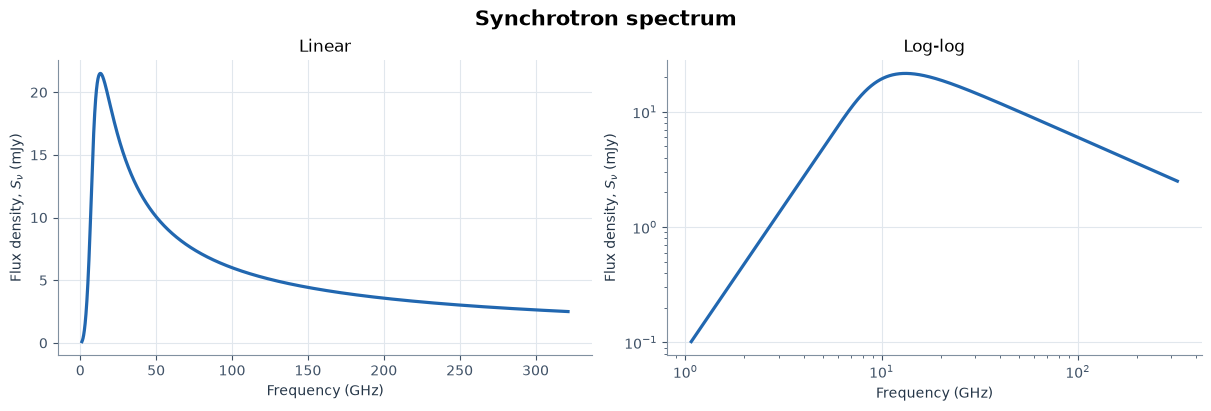

In [8]:
### USER INPUT VARIABLES HERE ###
# magnetic field in Gauss
B=1.9
# solid angle of source from size and distance of source
# distance in kpc then convert to cm
d=3.0
d=d*(3.1e21)
# size of blob here
# for an X-ray binary this might be something like 15 light minutes (3e13cm) across 
(r,V)=sizefromt(1800.0,cs)

# Illustrative radius scaling from the original example.
r=r*0.07
V=(4.0/3.0)*np.pi*r**3

omega=solidangle(r,d)
# Normalisation of N(E)=N0*E**(-p), not total number density
# I chose a value here which is more or less fits flux density seen for an X-ray binary
# at the adopted distance; this is an illustrative normalisation
N0=0.0045
p=2.5
#############################


nu1=nutau1(r,p,N0,B)

print (nu1)

SF=SFtau1(B,nu1,p)

x=np.linspace(nu1/10.0,nu1*30.0,10000)
y=F(x,nu1,SF,omega,p)
show_figure(plot_linear_log(x/1e9, y, "Frequency (GHz)", r"Flux density, $S_\nu$ (mJy)",
                            title="Synchrotron spectrum"))


## Time evolution of synchotron emission

Now, we can begin to explore how this spectrum might change as the source we have just defined, expands.

One of the earliest models which explored such evolution was that of van der Laan (1966) 

http://adsabs.harvard.edu/abs/1966Natur.211.1131V

(beware though, there are typos!)

This model considered an synchrotron-emitting 'blob' (also known as a 'plasmon' in some circles) which was expanding. As a result of the expansion, and consequent adiabatic expansion losses, the number density of emitting electrons varies as $N_0 \propto R^{-(2+p)}$. The magnetic field is assumed to evolve according to magnetic flux conservation $B \propto R^{-2}$. 

We can now take the spectrum we previously calculated, and see how it would have looked when the source was a factor of 2 smaller, and a factor of two larger (for linear expansion with time, this would correspond to $t=1,2,4$):

(NB the previous code cell needs to have been run before this one)

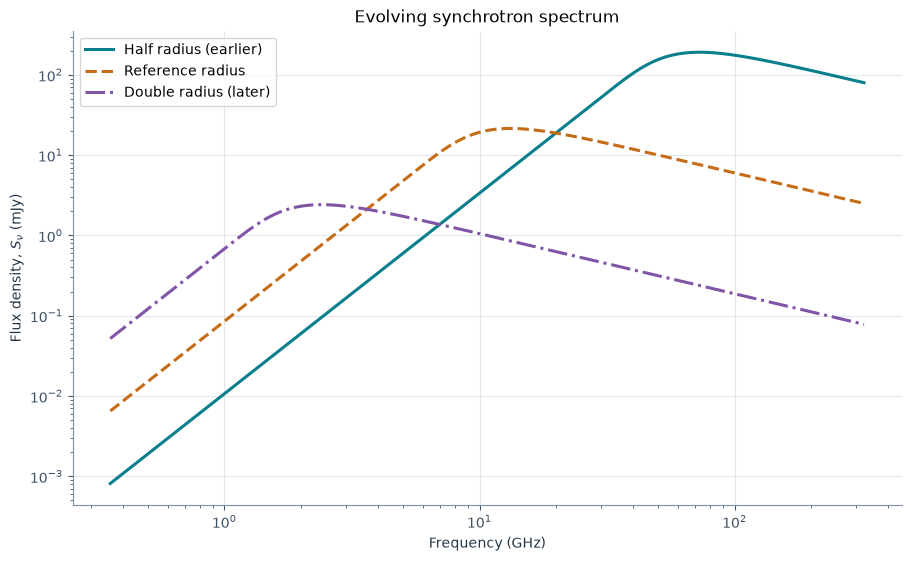

In [9]:
nu1=nutau1(r,p,N0,B)
SF=SFtau1(B,nu1,p)

x=np.linspace(nu1/30.0,nu1*30.0,100000)

# need to create functions for spectrum for source half and double size (assume p constant)
# here for double
sb=r*2.0
N0b=N0*(2.0**(-(2+p)))
Bb=B*(2.0**(-2.0))

nu1b=nutau1(sb,p,N0b,Bb)
SFb=SFtau1(Bb,nu1b,p)

# here for half
sc=r*0.5
N0c=N0*(0.5**(-(2+p)))
Bc=B*(0.5**(-2.0))

nu1c=nutau1(sc,p,N0c,Bc)
SFc=SFtau1(Bc,nu1c,p)

y=F(x,nu1,SF,omega,p)
yb=F(x,nu1b,SFb,omega*4.0,p)
yc=F(x,nu1c,SFc,omega/4.0,p)

show_figure(plot_spectra(x, [yc,y,yb],
    ["Half radius (earlier)", "Reference radius", "Double radius (later)"],
    savepath="output/graphs/Synch3panes.png"))


What is apparent, then, is that as our synchrotron-emitting source expands, the flux on the optically thin branch (above the peak) drops and the flux on the optically thick branch (below the peak) rises. This is a consequence of the peak of spectrum (whose optical depth depends on $p$; $\tau\simeq0.35$ applies to $p=2$) moving to lower frequencies as the magnetic field and number density, and hence opacity, decrease.

A large range of models for transient radio emission can be produced by simply playing with how the radius varies with time, and the number density and magnetic field vary with the radius.

Let's implement a complete van der Laan model next.

### An implementation of van der Laan's expanding blob

#### Radio light curves as a function of frequency

In [10]:
# MODEL INPUTS - all constants and physical equations remain here.
p = 2.5                         # choose 1.5, 2.0 or 2.5 for the tabulated coefficients
r0 = 3.0e9                      # initial radius (cm), at t=0
v = cs                          # constant expansion speed (cm/s)
d = 8.0 * 3.1e21                # distance (cm)
B0 = 1.0e3                      # initial magnetic field (gauss)
N00 = 1.0e12                    # initial electron distribution normalisation
observing_hz = np.array([140e6, 1.4e9, 16e9])
observing_labels = ["140 MHz", "1.4 GHz", "16 GHz"]
model_times = np.linspace(1.0, 500.0, 1200)  # seconds


def radius(t):
    return r0 + v*np.asarray(t)


def Br(r):
    return B0*(r/r0)**(-2)


def N0r(r):
    return N00*(r/r0)**(-(2+p))


model_radii = radius(model_times)
model_fields = Br(model_radii)
model_normalisations = N0r(model_radii)
model_omega = np.pi*(model_radii/d)**2
# Match the surrounding numerical model: effective line-of-sight depth s=R.
model_nu1 = nutau1(model_radii,p,model_normalisations,model_fields)
model_sf = SFtau1(model_fields,model_nu1,p)
# Include the turnover throughout playback, including the early high-frequency peak.
frequency_hz = np.geomspace(min(3e6, model_nu1.min()/3),
                            max(500e9, model_nu1.max()*3), 500)
# Broadcasting gives (n_times,n_frequencies) and (n_times,3) flux arrays.
model_spectra = F(frequency_hz[None,:], model_nu1[:,None],
                  model_sf[:,None], model_omega[:,None], p)
model_lightcurves = F(observing_hz[None,:], model_nu1[:,None],
                      model_sf[:,None], model_omega[:,None], p)

# PHYSICAL DIAGNOSTICS for one adiabatically cooling reference electron.
# gamma0 is defined at R=r0, not at the first plotted model time.
reference_gamma0 = 1.0e5
reference_gamma = reference_gamma0*(model_radii/r0)**(-1)
if np.min(reference_gamma) < 10:
    raise ValueError("Increase reference_gamma0 to keep the reference electron relativistic.")
reference_synchrotron_hz = 2.8e6*reference_gamma**2*model_fields
# Magnetic flux through an idealised comoving cross-section; conserved for B ∝ R^-2.
model_magnetic_flux = np.pi*model_radii**2*model_fields
# Normalise to the first model time so different units can share one axis.
diagnostic_x = model_radii/r0
diagnostic_values = np.column_stack([
    model_fields/model_fields[0],
    model_normalisations/model_normalisations[0],
    reference_synchrotron_hz/reference_synchrotron_hz[0],
    model_magnetic_flux/model_magnetic_flux[0],
])
diagnostic_labels = [r"Field $B\propto R^{-2}$",
                     r"Electron normalisation $N_0\propto R^{-(p+2)}$",
                     r"Reference electron $\nu_{syn}\propto R^{-4}$",
                     r"Magnetic flux $\Phi_B$: constant"]


### Animation: spectrum, two light-curve views, and physical diagnostics

The calculations above supply the same arrays to the plots. `synchrotron_plotting.py` only draws and exports figures; equations, coefficients, and model parameters remain in this notebook.

The three panels show the **spectrum**, **linear-linear light curves**, and **log-log light curves**. The light curves grow only up to the displayed time. Colours connect each observing frequency to its point on the spectrum; all axes stay fixed. A separate figure below explains the physical evolution of $B$, $N_0$, magnetic flux and the reference-electron frequency.

The separate diagnostic figure distinguishes magnetic **field strength** $B\propto R^{-2}$ from magnetic **flux** $\Phi_B=\pi R^2B$, which remains constant in this idealised flux-frozen model. “Electron frequency” here means the characteristic synchrotron frequency of one reference electron, not the spectral turnover or orbital frequency. Adiabatic cooling gives $\gamma\propto R^{-1}$ and hence $\nu_{\rm syn}\sim2.8\times10^6\gamma^2B\propto R^{-4}$. Each quantity is normalised to its value at the first model time (1 s, also the first animation frame). The chosen reference electron stays relativistic throughout the plotted range.

The notebook uses a **GIF without executable JavaScript**, with a PNG fallback for restricted viewers. It loops automatically. For play/pause, stepping, and a slider, open `output/graphs/evolving_synchrotron.html`; both exports work offline. If your editor blocks rich output, rerun this cell (or trust the notebook) or open `output/graphs/evolving_synchrotron.gif` directly. Earlier static spectrum plots and the completed static light curves below are retained.

**Key result:** $B\propto R^{-2}$, $\Phi_B$ is constant, and the reference electron has $\nu_{\rm syn}\propto R^{-4}$. The linear light-curve panel includes an early-time inset.


Saved: output/graphs/evolving_synchrotron.gif (inline/offline)
Saved: output/graphs/evolving_synchrotron.html (browser controls)


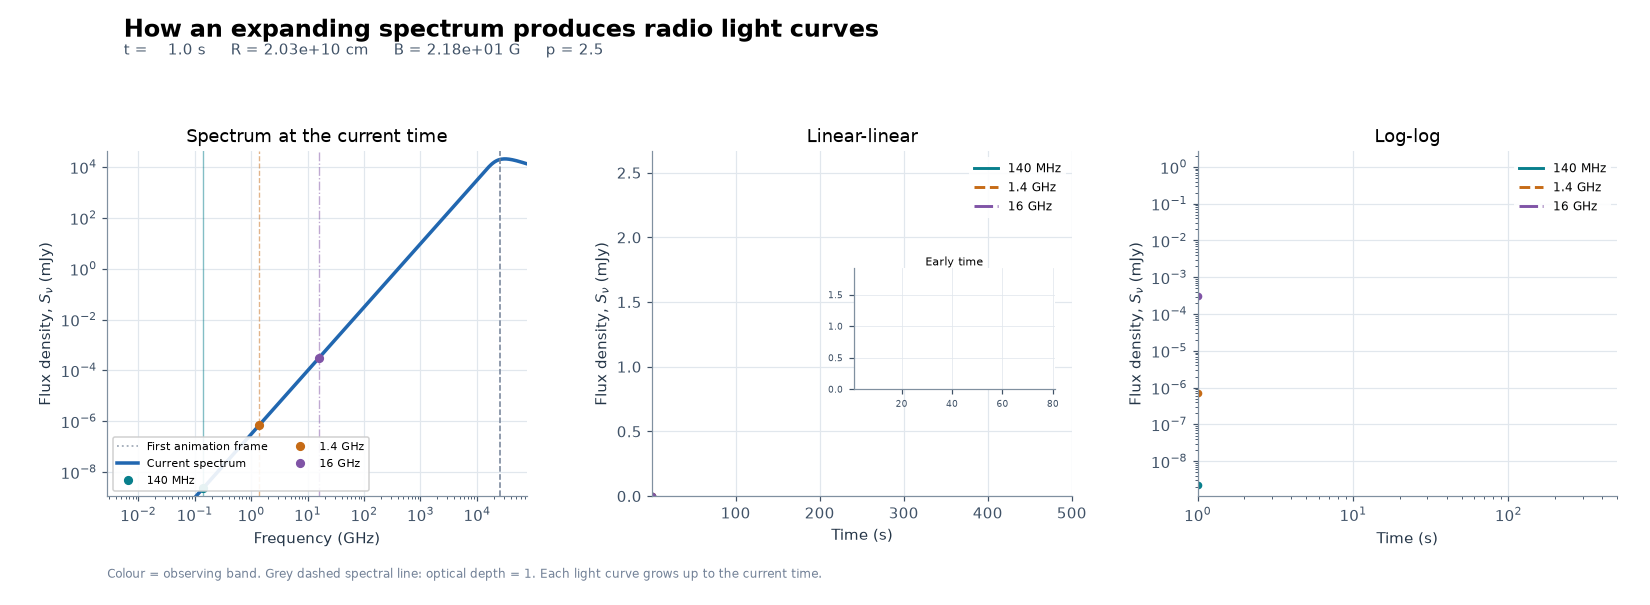

In [11]:
# Only playback settings and a plotting call; model maths stays in the cell above.
# Playback begins at the first model time, 1 s.
animation_frames = 90
animation_fps = 10
frame_indices = np.linspace(0,
                            len(model_times)-1, animation_frames, dtype=int)
evolution_movie = animate_evolution(
    model_times, frequency_hz, model_spectra, observing_hz, model_lightcurves,
    model_radii, model_fields, model_nu1,
    p=p, labels=observing_labels,
    frame_indices=frame_indices, fps=animation_fps,
)
evolution_movie.save("output/graphs").display()
print("Saved: output/graphs/evolving_synchrotron.gif (inline/offline)")
print("Saved: output/graphs/evolving_synchrotron.html (browser controls)")


### Completed light curves (still figure)

These panels show the full curves traced in the animation, on linear-linear and log-log axes. Both use exactly the same flux data. Keep this output for copying into notes or for viewers that cannot display animation.


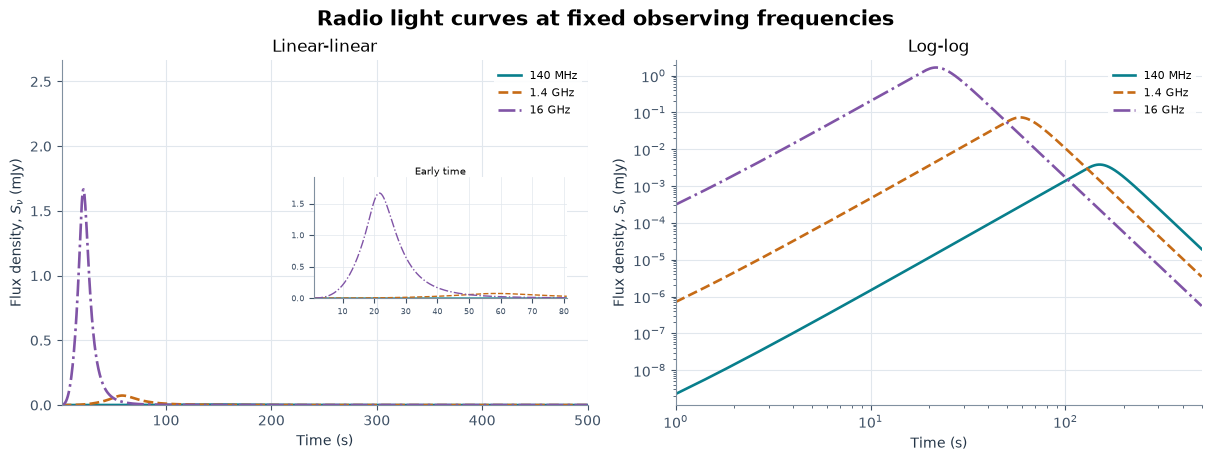

In [12]:
show_figure(plot_lightcurves(model_times, model_lightcurves, observing_labels,
                              savepath="output/graphs/lightcurves.png"))


### Physical evolution: field strength and the electron distribution

> **Definitions:** $B$ is magnetic field strength. $N_0$ is the normalisation of the energy distribution $N(E)=N_0E^{-p}$, **not** the total electron number density. $\Phi_B=\pi R^2B$ is magnetic flux through the idealised comoving cross-section.

> **Key results:** $B\propto R^{-2}$, $N_0\propto R^{-(p+2)}$ (here $R^{-4.5}$), $\nu_{\rm syn}\propto R^{-4}$ for the reference electron, and $\Phi_B$ is constant.

The normalisation changes through both dilution and adiabatic shifts of electron energies. For conserved particles with consistently evolving energy limits, total number density instead scales as $R^{-3}$. All plotted diagnostics are divided by their values at 1 s, so quantities with different units can share an axis. The upper axis maps the same expansion factors to model time. This figure explains the changing plasma; it is separate from the spectrum-to-light-curve animation.


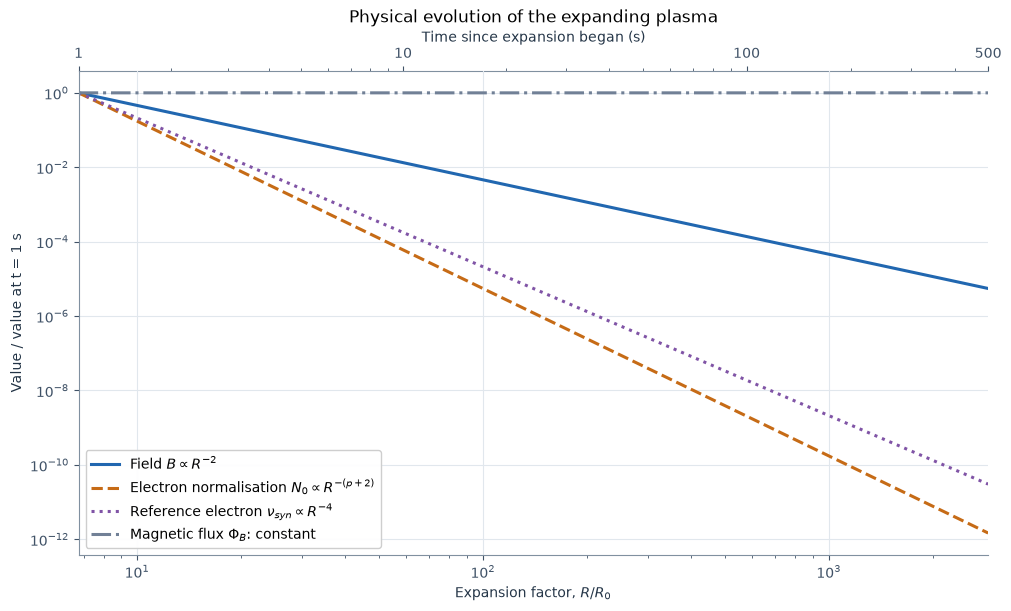

In [13]:
show_figure(plot_plasma_evolution(diagnostic_x, diagnostic_values, diagnostic_labels,
    times=model_times, savepath="output/graphs/plasma_evolution.png"))


It is clear from the log-log plot that the both the rise and decay phases have a power-law behaviour with time. This can be explicitly calculated by putting the van der Laan dependencies into the equations above, for linear expansion. In this case we get $S_{\nu} \propto t^3$ for the rising (optically thick) phase (once $R(t) >> R_0$) and $S_{\nu} \propto t^{-2p}$ in the decay (optically thin) phase (and recall the example uses $p=2.5$ so $S_{\nu} \propto t^{-5}$; $p=2$ would give $t^{-4}$).

More general solutions can be derived. If radius, magnetic field and number density evolve as

$$R(t) \propto t^a$$

$$B(t) \propto R(t)^b \propto t^{ab}$$

$$N_0(t) \propto R(t)^c \propto t^{ac}$$

then 

$$F_{thick} \propto t^u$$ where $$u={a\left( 2- \frac{b}{2} \right)}$$

and

$$F_{thin} \propto t^v$$ where $$v={a \left(3+c+b\frac{[p+1]}{2} \right)}$$

Check that inserting the van der Laan conditions of $a=1$, $b=-2$ and $c=-(2+p)$ recovers the correct evolution.

Note the very strong dependence of peak flux on frequency. This is *not* observed in many events which otherwise show 'van der Laan-like' evolution from optically thick to optically thin.

*This completes the first chapter of the crash course in radio transients. Part two will include more physical interpretation of data, consideration of the effects of special relativity and models for supernovae and gamma-ray bursts.*

### Model assumptions and limitations

- The source is homogeneous and uses an effective slab depth $s=R$; exact spherical transfer and filling-factor geometry change order-unity factors.
- The illustrative radius multiplier `0.07` in the static spectrum is retained as an explicit input choice, not an inferred physical result.
- Characteristic electron frequencies omit pitch-angle and exact spectral-kernel factors. The reference-electron diagnostic follows one representative electron and is not the frequency of the whole source's spectral peak.
- The expansion model assumes constant speed, magnetic flux freezing and adiabatic losses. It does not include new particle injection, synchrotron/inverse-Compton cooling, external absorption, or a detailed magnetic topology.
- Relativistic Doppler boosting, cosmological redshift, and light-travel effects across the source are omitted. Brightness-temperature and variability-size arguments have corresponding assumptions.
- The minimum-energy estimate depends on geometry, unseen particles and frequency cutoffs. It is not a measurement proving equipartition.
- Only $p=1.5,2.0,2.5$ have tabulated coefficient pairs here. Use a consistent coefficient calculation before choosing other indices.
